Left Eye:


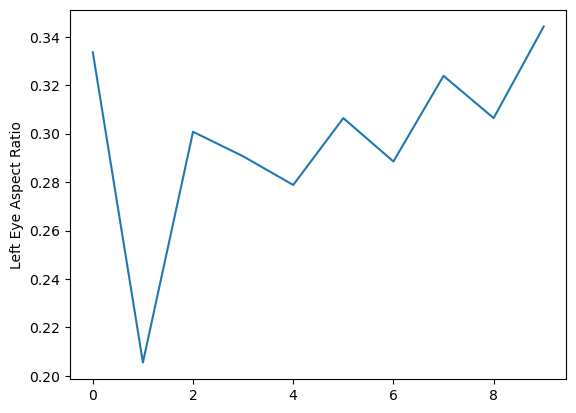

Average Left Eye Aspect Ratio 0.2978818121482051

Right Eye:


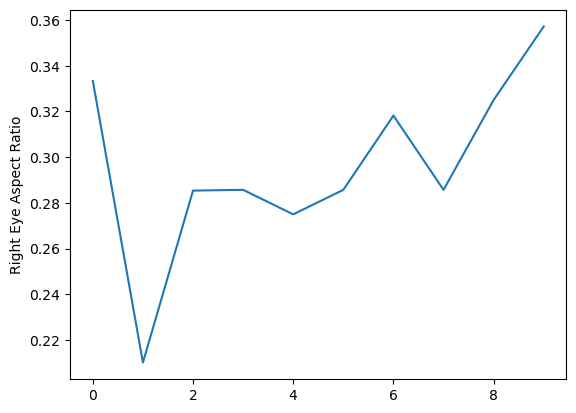

Average Right Eye Aspect Ratio 0.2961427094784617

Diagnosis:
No Ptosis suspected in Left Eye.
No Ptosis suspected in Right Eye.


In [1]:
import cv2
import dlib
from imutils import face_utils
from scipy.spatial import distance as dist
import math
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np

left_EAR=[]
right_EAR=[]
average_right_EAR=0
average_left_EAR=0
EYE_AR_THRESH = 0.275

face_detector = dlib.get_frontal_face_detector()
eyes_detector = dlib.shape_predictor("shape_predictor_68_face_landmarks.dat")


def eye_aspect_ratio(eye):
    # compute the euclidean distances between the two sets of
    # vertical eye landmarks (x, y)-coordinates
    A = dist.euclidean(eye[1], eye[5])
    B = dist.euclidean(eye[2], eye[4])

    # compute the euclidean distance between the horizontal
    # eye landmark (x, y)-coordinates
    C = dist.euclidean(eye[0], eye[3])

    # compute the eye aspect ratio
    ear = (A + B) / (2.0 * C)

    # return the eye aspect ratio
    return ear

def main():
    cap = cv2.VideoCapture(0)
    
    
    while True:
        _, frame = cap.read()
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

        faces = face_detector(gray)
        for face in faces:

            eyes = eyes_detector(gray, face)        
            
            for n in range(36, 48):
                x = eyes.part(n).x
                y = eyes.part(n).y
                cv2.circle(frame, (x, y), 1, (0, 255, 255), 1)
                
            eyes = face_utils.shape_to_np(eyes)

            # extract the left and right eye coordinates, then use the
            # coordinates to compute the eye aspect ratio for both eyes
            (lStart, lEnd) = face_utils.FACIAL_LANDMARKS_IDXS["left_eye"]
            (rStart, rEnd) = face_utils.FACIAL_LANDMARKS_IDXS["right_eye"]            
            
            leftEye = eyes[lStart:lEnd]           
            leftEAR = eye_aspect_ratio(leftEye)
            if (leftEAR >0):
                left_EAR.append(leftEAR)
            
            rightEye = eyes[rStart:rEnd]
            rightEAR = eye_aspect_ratio(rightEye)
            if (rightEAR >0):
                right_EAR.append(rightEAR)
            
            cv2.imshow("Eyes", frame)
            
        key = cv2.waitKey(1)
        if key == 27:
            break
            
    print('Left Eye:')
    plt.plot(left_EAR)
    plt.ylabel('Left Eye Aspect Ratio')
    plt.show()
    if (len(left_EAR)>0):
        average_left_EAR = sum(left_EAR)/ len(left_EAR)
        print('Average Left Eye Aspect Ratio', average_left_EAR)
        
        
    print()    
    print('Right Eye:')
    plt.plot(right_EAR)
    plt.ylabel('Right Eye Aspect Ratio')
    plt.show()
    if (len(right_EAR)>0):
        average_right_EAR = sum(right_EAR)/ len(right_EAR)
        print('Average Right Eye Aspect Ratio', average_right_EAR) 
        
    print()
    print('Diagnosis:')
    
    if (average_left_EAR>0):
        if (average_left_EAR)< EYE_AR_THRESH:
            print ('Ptosis suspected in Left Eye, please consult a medical professional.')
        else:
            print ('No Ptosis suspected in Left Eye.')
    else:
        print ('Unable to diagnose Left Eye.')
    
    if (average_right_EAR>0):
        if (average_right_EAR)< EYE_AR_THRESH:
            print ('Ptosis suspected in Right Eye, please consult a medical professional.')
        else:
            print ('No Ptosis suspected in Right Eye.') 
    else:
        print ('Unable to diagnose Right Eye.')
        
    cap.release()
    cv2.destroyAllWindows()

if __name__ == "__main__":
    main()